# B3 — Histogram dan Perbaikan Citra (SIMUTEH)
Nama: Try Dymaz Prayoga · NIM 2330511020 · **SEED = 1020**

In [1]:
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik
def muat(nama, folder="citra"):
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

## Langkah 3.1 Lembar hitung manual (verifikasi dengan kode)

a) histogram: {1: 2, 2: 7, 3: 6, 4: 1}


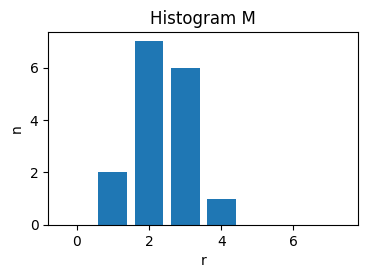

b) peregangan s = (r-1)/(4-1)*7:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
c)
 r  n    PDF    CDF  7xCDF  s
 1  2 0.1250 0.1250 0.8750  1
 2  7 0.4375 0.5625 3.9375  4
 3  6 0.3750 0.9375 6.5625  7
 4  1 0.0625 1.0000 7.0000  7
Matriks hasil ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
d) negatif r=60: 195
   kontras r=120: 1,4*120-30 = 138 -> clip = 138
   kontras r=210: 1,4*210-30 = 264 -> clip = 255
   gamma 0.6: 255*(100/255)^0.6 = 145.42 -> 145
   gamma 1.8: 255*(100/255)^1.8 = 47.29 -> 47


In [2]:
M = np.array([[1, 2, 2, 3], [2, 2, 3, 3], [1, 2, 3, 4], [2, 3, 3, 2]])
L = 8
# a) histogram
r, n = np.unique(M, return_counts=True)
print("a) histogram:", dict(zip(r.tolist(), n.tolist())))
plt.figure(figsize=(4, 2.5)); plt.bar(range(L), np.bincount(M.ravel(), minlength=L))
plt.xlabel("r"); plt.ylabel("n"); plt.title("Histogram M"); plt.savefig("../hasil/b3_hist_manual.png"); plt.show()
# b) peregangan ke 0..7
reg = np.round((M - M.min()) / (M.max() - M.min()) * (L - 1)).astype(int)
print("b) peregangan s = (r-1)/(4-1)*7:\n", reg)
# c) ekualisasi
pdf = n / M.size; cdf = np.cumsum(pdf); s = np.round((L - 1) * cdf).astype(int)
print("c)"); print(pd.DataFrame({"r": r, "n": n, "PDF": pdf.round(4), "CDF": cdf.round(4),
                    "7xCDF": ((L-1)*cdf).round(4), "s": s}).to_string(index=False))
peta = dict(zip(r, s)); print("Matriks hasil ekualisasi:\n", np.vectorize(peta.get)(M))
# d) operasi titik 8 bit
print("d) negatif r=60:", 255 - 60)
for rr in (120, 210):
    v = 1.4 * rr - 30; print(f"   kontras r={rr}: 1,4*{rr}-30 = {v:.0f} -> clip = {int(np.clip(v, 0, 255))}")
for g in (0.6, 1.8):
    print(f"   gamma {g}: 255*(100/255)^{g} = {255 * (100/255) ** g:.2f} -> {round(255 * (100/255) ** g)}")

## Langkah 3.2 Diagnosis mutu (Kode 3.1)

teh_041.png {'rerata': 167.9, 'simpangan_baku': 40.8, 'min': 52, 'maks': 233, 'persen_gelap': 0.0, 'persen_terang': 3.8}
teh_042.png {'rerata': 116.8, 'simpangan_baku': 37.1, 'min': 20, 'maks': 155, 'persen_gelap': 17.5, 'persen_terang': 0.0}
teh_043.png {'rerata': 212.4, 'simpangan_baku': 23.2, 'min': 135, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 77.1}
teh_044.png {'rerata': 149.6, 'simpangan_baku': 16.1, 'min': 90, 'maks': 198, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 118.5, 'simpangan_baku': 51.3, 'min': 22, 'maks': 237, 'persen_gelap': 2.4, 'persen_terang': 3.9}


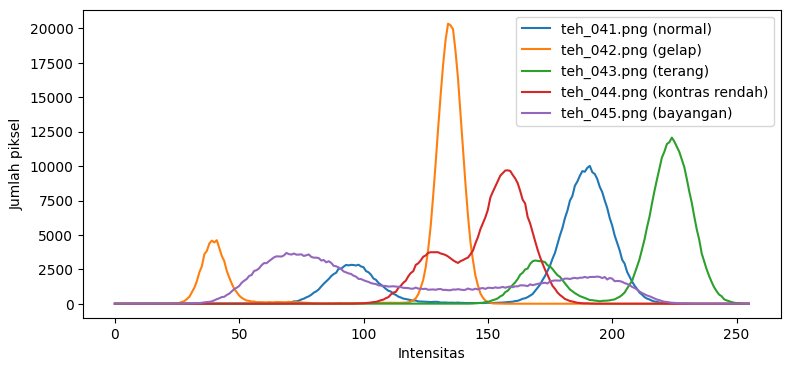

teh_021.png {'rerata': 169.9, 'simpangan_baku': 42.7, 'min': 70, 'maks': 224, 'persen_gelap': 0.0, 'persen_terang': 0.8}


teh_022.png {'rerata': 111.6, 'simpangan_baku': 38.3, 'min': 14, 'maks': 171, 'persen_gelap': 14.2, 'persen_terang': 0.0}
teh_023.png {'rerata': 208.7, 'simpangan_baku': 24.9, 'min': 140, 'maks': 249, 'persen_gelap': 0.0, 'persen_terang': 75.5}
teh_024.png {'rerata': 156.1, 'simpangan_baku': 14.9, 'min': 109, 'maks': 187, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 122.6, 'simpangan_baku': 52.0, 'min': 16, 'maks': 238, 'persen_gelap': 3.3, 'persen_terang': 4.6}


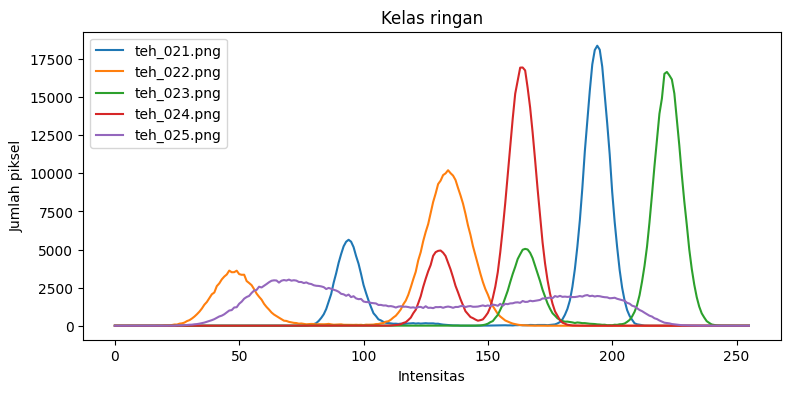

                       citra  rerata  simpangan_baku   min  maks  persen_gelap  persen_terang
            teh_041 (normal)   167.9            40.8  52.0 233.0           0.0            3.8
             teh_042 (gelap)   116.8            37.1  20.0 155.0          17.5            0.0
            teh_043 (terang)   212.4            23.2 135.0 254.0           0.0           77.1
    teh_044 (kontras rendah)   149.6            16.1  90.0 198.0           0.0            0.0
          teh_045 (bayangan)   118.5            51.3  22.0 237.0           2.4            3.9
teh_021-025 (ringan, rerata)   153.8            34.6  69.8 213.8           3.5           16.2


In [3]:
rows = []
plt.figure(figsize=(9, 4))
kondisi = {"teh_041.png": "normal", "teh_042.png": "gelap", "teh_043.png": "terang",
           "teh_044.png": "kontras rendah", "teh_045.png": "bayangan"}
for nama, kd in kondisi.items():
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    st = statistik(gray); print(nama, st); rows.append({"citra": f"{nama[:7]} ({kd})", **st})
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=f"{nama} ({kd})")
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png", dpi=120); plt.show()

# lima citra kelas ringan teh_021..teh_025
plt.figure(figsize=(9, 4)); st_r = []
for i in range(21, 26):
    nama = f"teh_{i:03d}.png"
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    st = statistik(gray); print(nama, st); st_r.append(st)
    plt.plot(cv2.calcHist([gray], [0], None, [256], [0, 256]), label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(); plt.title("Kelas ringan")
plt.savefig("../hasil/b3_histogram_ringan.png", dpi=120); plt.show()
rows.append({"citra": "teh_021-025 (ringan, rerata)", **pd.DataFrame(st_r).mean().round(1).to_dict()})
tabel9 = pd.DataFrame(rows); print(tabel9.to_string(index=False))
tabel9.to_csv("../hasil/b3_tabel9_diagnosis.csv", index=False)

## Langkah 3.3 Perbaikan citra kondisi bayangan (Kode 3.2)

asli       KB=2.53 sigma=51.3
negatif    KB=2.53 sigma=51.3
cerah+50   KB=2.53 sigma=50.8
kontras    KB=2.53 sigma=74.9
regang     KB=2.61 sigma=80.7
gamma0.5   KB=2.15 sigma=37.6
gamma1.8   KB=3.26 sigma=53.3
ekualisasi KB=1.74 sigma=73.3
CLAHE      KB=2.59 sigma=44.5


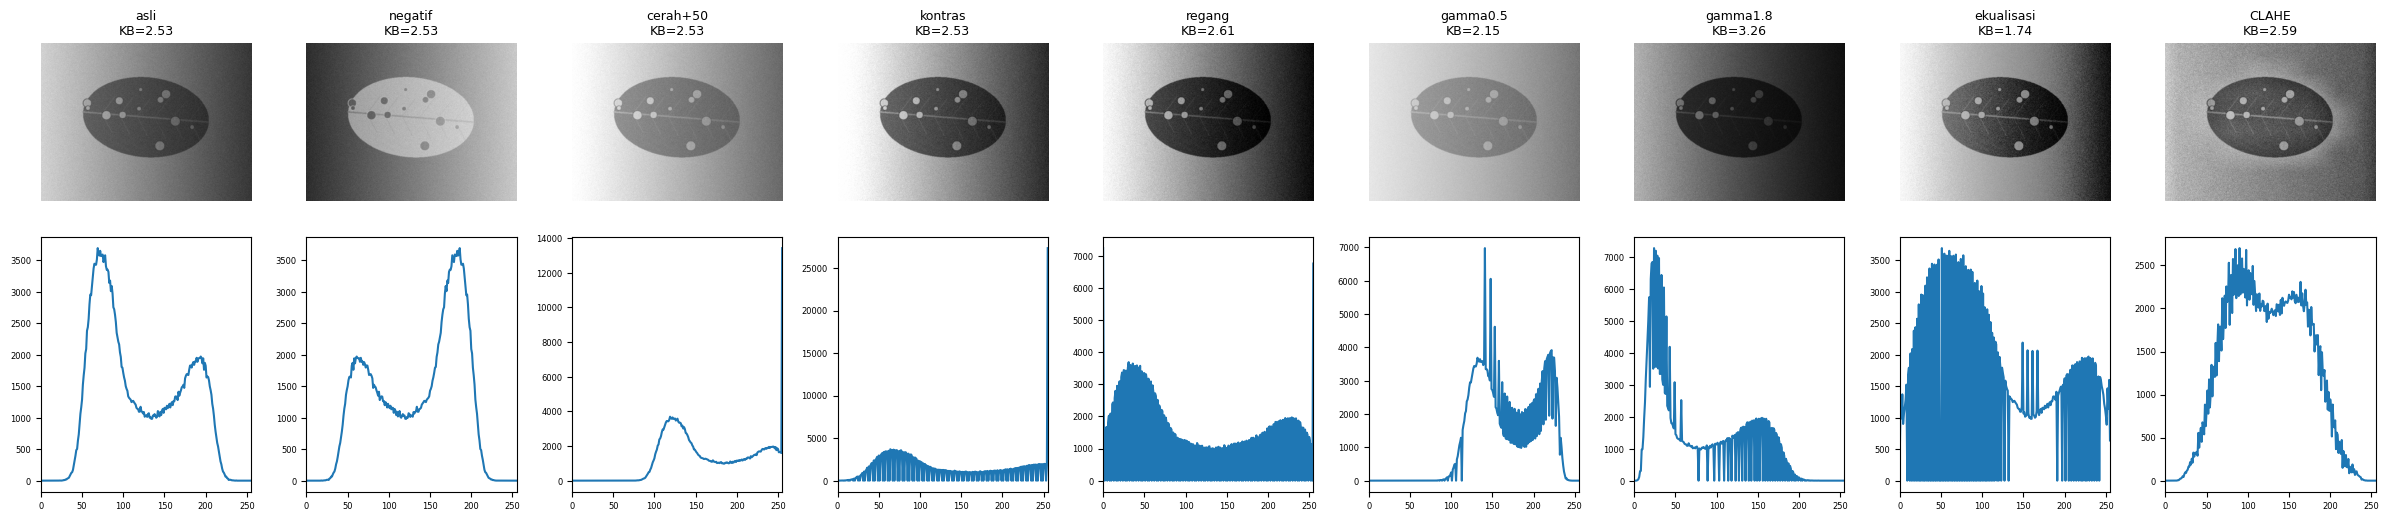

In [4]:
nama = "teh_045.png"  # kondisi bayangan
img, md, mb = muat(nama)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}
param = {"asli": "-", "negatif": "s = 255 - r", "cerah+50": "beta = +50", "kontras": "alpha 1,5; beta -40",
         "regang": f"persentil 2-98 ({rmin:.0f}-{rmax:.0f})", "gamma0.5": "gamma 0,5", "gamma1.8": "gamma 1,8",
         "ekualisasi": "global", "CLAHE": "clip 2,0; tile 8x8"}
t10 = []
for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    print(f"{nm:10s} KB={kb:.2f} sigma={c.std():.1f}")
    t10.append([nm, param[nm], round(kb, 2), round(float(c.std()), 1)])
tabel10 = pd.DataFrame(t10, columns=["metode", "parameter", "KB", "simpangan_baku"])
tabel10.to_csv("../hasil/b3_tabel10_perbaikan.csv", index=False)

# tata letak Gambar 4: citra di atas, histogram di bawah
fig, ax = plt.subplots(2, 9, figsize=(24, 5.5))
for i, (nm, c) in enumerate(hasil.items()):
    ax[0, i].imshow(c, cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(f"{nm}\nKB={kontras_bercak(c, md, mb):.2f}", fontsize=9); ax[0, i].axis("off")
    ax[1, i].plot(cv2.calcHist([c], [0], None, [256], [0, 256])); ax[1, i].set_xlim(0, 255); ax[1, i].tick_params(labelsize=6)
plt.tight_layout(); plt.savefig("../hasil/b3_perbaikan_bayangan.png", dpi=110); plt.show()

## Langkah 3.4 Eksperimen CLAHE (Kode 3.3)

clip=1.0 tile=4: KB=3.16
clip=1.0 tile=8: KB=2.95
clip=1.0 tile=16: KB=2.94
clip=2.0 tile=4: KB=2.91
clip=2.0 tile=8: KB=2.59
clip=2.0 tile=16: KB=2.47
clip=4.0 tile=4: KB=2.29
clip=4.0 tile=8: KB=2.07
clip=4.0 tile=16: KB=1.94


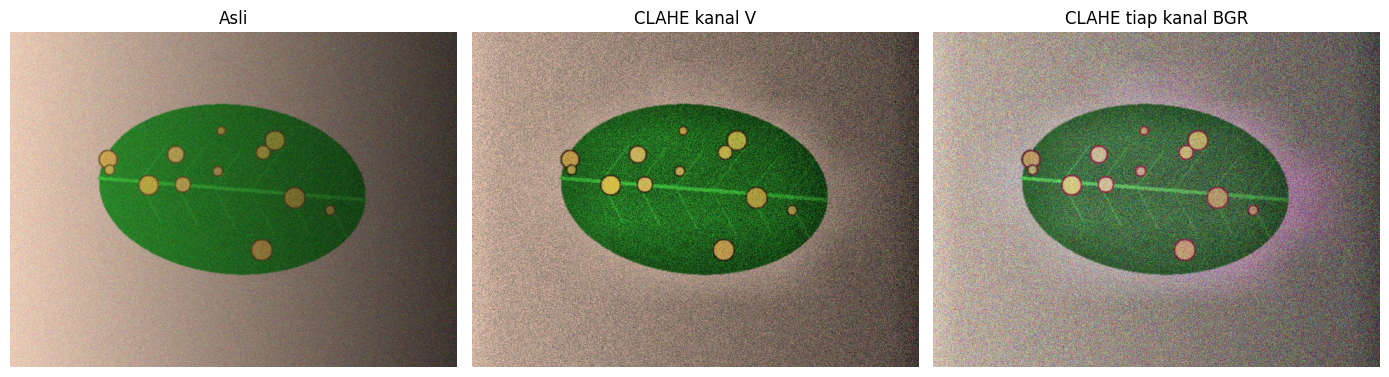

In [5]:
kb_clahe = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        kb = kontras_bercak(c, md, mb)
        print(f"clip={clip} tile={tile}: KB={kb:.2f}")
        kb_clahe.append([clip, tile, round(kb, 2)])
pd.DataFrame(kb_clahe, columns=["clipLimit", "tile", "KB"]).pivot(index="clipLimit", columns="tile", values="KB").to_csv("../hasil/b3_kb_clahe.csv")

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", dpi=110); plt.show()

In [6]:
# Bukti P3.4: pergeseran Hue di area daun sehat (rona warna seharusnya tidak berubah)
sehat = (md > 0) & (mb == 0)
def hue_rerata(x):
    return cv2.cvtColor(x, cv2.COLOR_BGR2HSV)[:, :, 0][sehat].astype(float)
h0 = hue_rerata(img)
for nm, x in [("CLAHE kanal V", via_v), ("CLAHE tiap BGR", via_bgr)]:
    h1 = hue_rerata(x); d = np.abs(h1 - h0); d = np.minimum(d, 180 - d)
    print(f"{nm:16s}: rerata |dH| daun sehat = {d.mean():.2f}, rerata H {h0.mean():.1f} -> {h1.mean():.1f}, "
          f"KB R = {kontras_bercak(x[:, :, 2], md, mb):.2f}, KB H = {kontras_bercak(cv2.cvtColor(x, cv2.COLOR_BGR2HSV)[:, :, 0], md, mb):.2f}")

CLAHE kanal V   : rerata |dH| daun sehat = 0.03, rerata H 59.3 -> 59.4, KB R = 8.33, KB H = 4.87
CLAHE tiap BGR  : rerata |dH| daun sehat = 15.57, rerata H 59.3 -> 65.2, KB R = 3.95, KB H = 0.21


## Langkah 3.5 Satu perbaikan per kondisi (kerjakan sendiri)
Perbaikan dipilih dari data, dengan **dua syarat**:
1. **Syarat arah:** rerata intensitas hasil harus bergeser *mendekati* rerata kondisi normal. Perbaikan yang menjauhkan (misalnya menggelapkan citra yang sudah gelap) ditolak, karena KB bisa naik hanya karena derau di daun gelap ikut tertekan, bukan karena bercak makin jelas.
2. Di antara kandidat yang lolos, pilih **rerata KB tertinggi** pada 8 citra per kondisi (4 berat + 4 ringan).

In [7]:
def regang(g):
    a, b = np.percentile(g, (2, 98))
    return np.clip((g.astype(float) - a) / max(b - a, 1) * 255, 0, 255).astype(np.uint8)
kandidat = {
    "gamma 0,5": lambda g: cv2.LUT(g, gamma_lut(0.5)),
    "gamma 0,7": lambda g: cv2.LUT(g, gamma_lut(0.7)),
    "gamma 1,5": lambda g: cv2.LUT(g, gamma_lut(1.5)),
    "gamma 1,8": lambda g: cv2.LUT(g, gamma_lut(1.8)),
    "regang 2-98": regang,
    "ekualisasi": cv2.equalizeHist,
    "CLAHE 1,0/8": lambda g: cv2.createCLAHE(1.0, (8, 8)).apply(g),
    "CLAHE 2,0/8": lambda g: cv2.createCLAHE(2.0, (8, 8)).apply(g),
}
label = pd.read_csv("../data/sintetis/label.csv")
target = np.mean([cv2.cvtColor(baca(f"../data/sintetis/citra/{n}"), cv2.COLOR_BGR2GRAY).mean()
                  for n in label[(label.kelas != "sehat") & (label.kondisi_cahaya == "normal")].nama_file])
print(f"Rerata intensitas kondisi normal (target) = {target:.1f}")
bb = []
for _, d in label[label.kelas != "sehat"].iterrows():
    if d.kondisi_cahaya == "normal": continue
    im, m_d, m_b = muat(d.nama_file); g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    for k, f in {"asli": lambda x: x, **kandidat}.items():
        o = f(g)
        bb.append([d.kondisi_cahaya, k, kontras_bercak(o, m_d, m_b), o.mean()])
seleksi = pd.DataFrame(bb, columns=["kondisi", "metode", "KB", "rerata"]).groupby(["kondisi", "metode"]).mean().round(2)
pilih = {}
for kd in seleksi.index.get_level_values(0).unique():
    t = seleksi.loc[kd]
    jarak_asli = abs(t.loc["asli", "rerata"] - target)
    t = t.assign(lolos_arah=(t.rerata - target).abs() <= jarak_asli)
    seleksi.loc[kd, "lolos_arah"] = t.lolos_arah.values
    kand = t[(t.index != "asli") & t.lolos_arah]
    pilih[kd] = kand.KB.idxmax()
print(seleksi.to_string()); seleksi.to_csv("../hasil/b3_seleksi_perbaikan.csv")
print("\nPerbaikan terpilih:", pilih)

Rerata intensitas kondisi normal (target) = 171.9


                              KB  rerata lolos_arah
kondisi        metode                              
bayangan       CLAHE 1,0/8  1.81  125.69       True
               CLAHE 2,0/8  1.72  126.81       True
               asli         1.31  123.26       True
               ekualisasi   0.99  128.33       True
               gamma 0,5    1.14  172.56       True
               gamma 0,7    1.20  149.84       True
               gamma 1,5    1.49   91.15      False
               gamma 1,8    1.61   77.60      False
               regang 2-98  1.34  110.58      False
gelap          CLAHE 1,0/8  2.62  126.95       True
               CLAHE 2,0/8  1.93  128.12       True
               asli         3.71  123.68       True
               ekualisasi   0.90  131.22       True
               gamma 0,5    2.90  173.24       True
               gamma 0,7    3.20  150.55       True
               gamma 1,5    4.67   90.00      False
               gamma 1,8    5.32   75.19      False
            

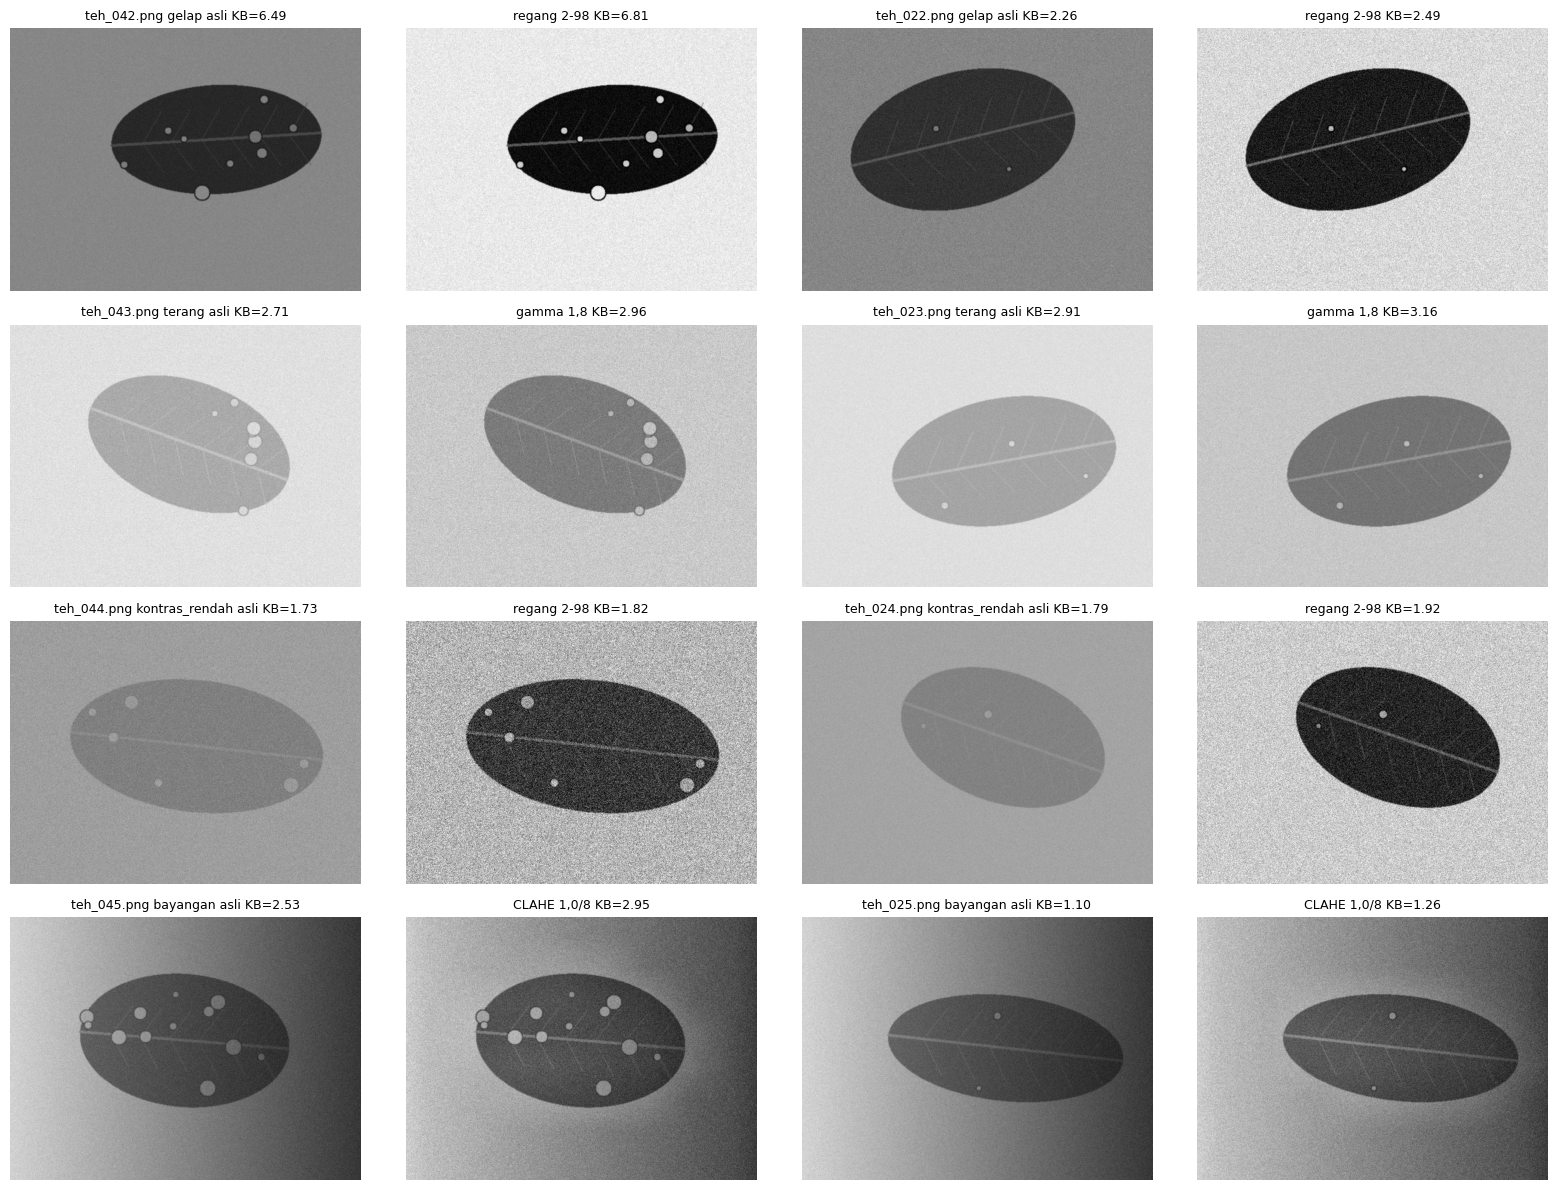

       kondisi       citra   perbaikan  KB_sebelum  KB_sesudah
         gelap teh_042.png regang 2-98        6.49        6.81
         gelap teh_022.png regang 2-98        2.26        2.49
        terang teh_043.png   gamma 1,8        2.71        2.96
        terang teh_023.png   gamma 1,8        2.91        3.16
kontras_rendah teh_044.png regang 2-98        1.73        1.82
kontras_rendah teh_024.png regang 2-98        1.79        1.92
      bayangan teh_045.png CLAHE 1,0/8        2.53        2.95
      bayangan teh_025.png CLAHE 1,0/8        1.10        1.26


In [8]:
pasangan = {"gelap": ("teh_042.png", "teh_022.png"), "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"), "bayangan": ("teh_045.png", "teh_025.png")}
baris35 = []
fig, ax = plt.subplots(4, 4, figsize=(16, 12))
for i, (kd, (nm_b, nm_r)) in enumerate(pasangan.items()):
    jd = pilih[kd]; f = kandidat[jd]
    for j, nm in enumerate([nm_b, nm_r]):
        im, m_d, m_b = muat(nm); g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY); out = f(g)
        kb0, kb1 = kontras_bercak(g, m_d, m_b), kontras_bercak(out, m_d, m_b)
        baris35.append([kd, nm, jd, round(kb0, 2), round(kb1, 2)])
        ax[i, 2*j].imshow(g, cmap="gray", vmin=0, vmax=255); ax[i, 2*j].set_title(f"{nm} {kd} asli KB={kb0:.2f}", fontsize=9)
        ax[i, 2*j+1].imshow(out, cmap="gray", vmin=0, vmax=255); ax[i, 2*j+1].set_title(f"{jd} KB={kb1:.2f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b3_perbaikan_4kondisi.png", dpi=100); plt.show()
t35 = pd.DataFrame(baris35, columns=["kondisi", "citra", "perbaikan", "KB_sebelum", "KB_sesudah"])
print(t35.to_string(index=False)); t35.to_csv("../hasil/b3_perbaikan_4kondisi.csv", index=False)

### Aturan sederhana berbasis statistik histogram (bukti P3.5)
Fitur: rerata, simpangan baku, dan selisih rerata seperempat kiri dan kanan citra (penanda bayangan).

In [9]:
def fitur_cahaya(g):
    w = g.shape[1] // 4; g = g.astype(float)
    return g.mean(), g.std(), abs(g[:, :w].mean() - g[:, -w:].mean())

def deteksi_kondisi(g):
    m, s, lr = fitur_cahaya(g)
    if lr > 40: return "bayangan"
    if m > 190: return "terang"
    if s < 25: return "kontras_rendah"
    if m < 145: return "gelap"
    return "normal"

rr = []
for _, d in label.iterrows():
    g = cv2.cvtColor(baca(f"../data/sintetis/citra/{d.nama_file}"), cv2.COLOR_BGR2GRAY)
    m, s, lr = fitur_cahaya(g)
    rr.append([d.kondisi_cahaya, m, s, lr, deteksi_kondisi(g)])
rr = pd.DataFrame(rr, columns=["kondisi", "rerata", "std", "selisih_kiri_kanan", "prediksi"])
print(rr.groupby("kondisi")[["rerata", "std", "selisih_kiri_kanan"]].agg(["min", "max"]).round(1))
print(pd.crosstab(rr.kondisi, rr.prediksi))
print(f"Akurasi aturan pada 60 citra: {(rr.kondisi == rr.prediksi).mean():.1%}")
# pembanding: tanpa fitur kiri-kanan
def tanpa_lr(m, s):
    if m > 190: return "terang"
    if s < 25: return "kontras_rendah"
    if s > 47: return "bayangan"
    if m < 145: return "gelap"
    return "normal"
print(f"Akurasi tanpa fitur kiri-kanan (std > 47 = bayangan): {(rr.kondisi == [tanpa_lr(a, b) for a, b in zip(rr.rerata, rr['std'])]).mean():.1%}")

               rerata          std       selisih_kiri_kanan       
                  min    max   min   max                min    max
kondisi                                                           
bayangan        118.1  127.8  48.4  56.3              107.0  128.6
gelap           111.6  137.3  36.5  48.1                3.4   21.8
kontras_rendah  149.6  158.3  12.2  18.0                1.9    7.0
normal          167.9  178.6  35.2  45.6                2.2   16.8
terang          205.9  214.9  23.2  30.1                0.3   15.6
prediksi        bayangan  gelap  kontras_rendah  normal  terang
kondisi                                                        
bayangan              12      0               0       0       0
gelap                  0     12               0       0       0
kontras_rendah         0      0              12       0       0
normal                 0      0               0      12       0
terang                 0      0               0       0      12
Akurasi aturan p